# RV32I pipelined core: run every test in the browser

Runs the whole verification suite on a free Colab machine: directed tests,
random tests against the Python reference model, the planted-bug hunt, and the
waveform pictures. **Runtime → Run all**, then read the outputs below each cell.

In [1]:
# 1. install the Verilog simulator and get the code (about 1 minute)
!apt-get -qq install iverilog > /dev/null
!git clone -q https://github.com/Raushan-kumar0/riscv-pipeline-rv32i.git
%cd riscv-pipeline-rv32i
!iverilog -V 2>&1 | head -1

/content/riscv-pipeline-rv32i
Icarus Verilog version 12.0 (stable) ()


In [2]:
# 2. six hand-written self-checking programs
!python scripts/run.py directed

Directed tests:
  alu_test     [PASS] cycles=124 instret=118 CPI=1.051
  mem_test     [PASS] cycles=100 instret=94 CPI=1.064
  branch_test  [PASS] cycles=128 instret=80 CPI=1.600
  hazard_test  [PASS] cycles=103 instret=88 CPI=1.170
  bubble_sort  [PASS] cycles=6289 instret=4242 CPI=1.483
  fib          [PASS] cycles=219 instret=157 CPI=1.395

6/6 directed tests passed


In [3]:
# 3. 100 random programs x 400 instructions, Verilog core vs Python reference model
!python scripts/run.py random --seeds 100 --len 400

Random regression: 100 programs x 400 random instructions

100/100 programs matched the reference model (39804 instructions executed in total)


### Planted-bug hunt
Each bug is switched on alone and every test is re-run. Broken cores often get
stuck in loops and must hit the 200,000-cycle timeout, so this cell takes
roughly 10 minutes on Colab.

In [4]:
# 4. does the test suite catch deliberately broken hardware?
!python scripts/run.py bugs --seeds 100 --len 400

Bug hunt: each planted bug is switched on alone, then all tests run.

  bug                  directed tests failing   random seeds failing
  BUG_NO_EXMEM_FWD     6/6                      100/100
  BUG_NO_LOAD_STALL    2/6                      70/100
  BUG_NO_FLUSH_IFID    3/6                      100/100
  BUG_SRA_AS_SRL       1/6                      30/100

4/4 planted bugs were detected


[PASS] cycles=103 instret=88 CPI=1.170
waveform written to /content/riscv-pipeline-rv32i/build/wave.vcd
wrote docs/waveform_load_use_stall.png
wrote docs/waveform_jalr_flush.png


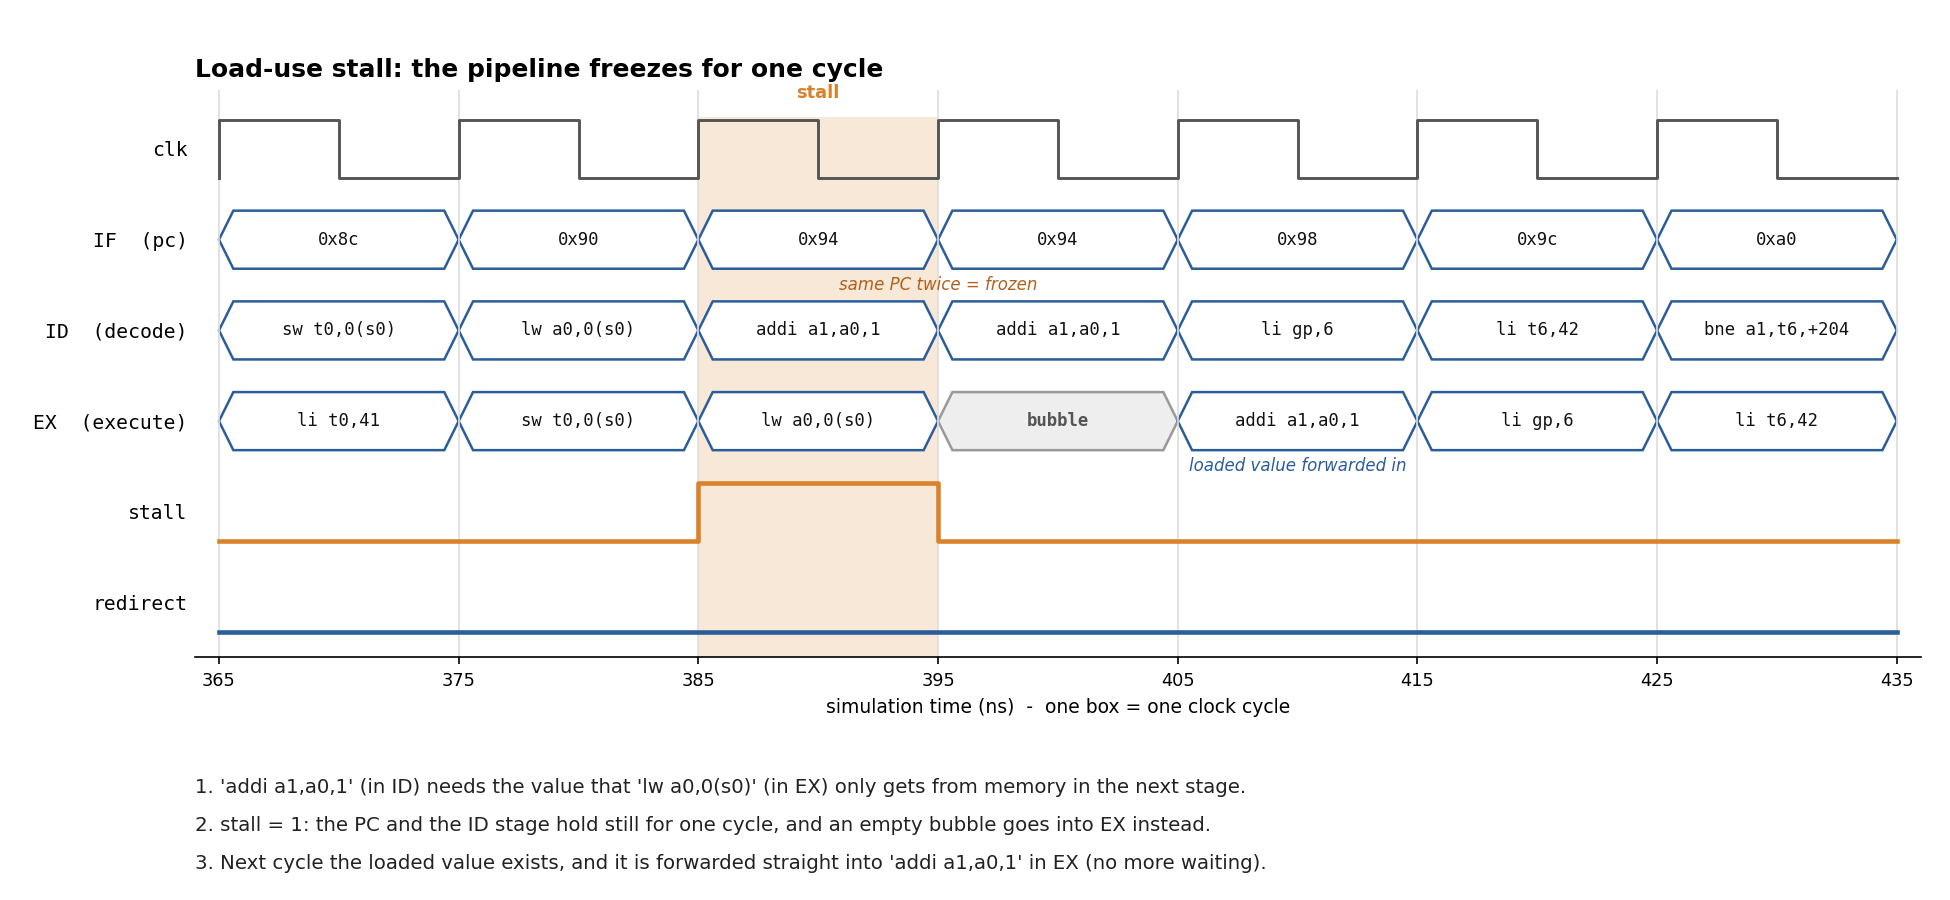

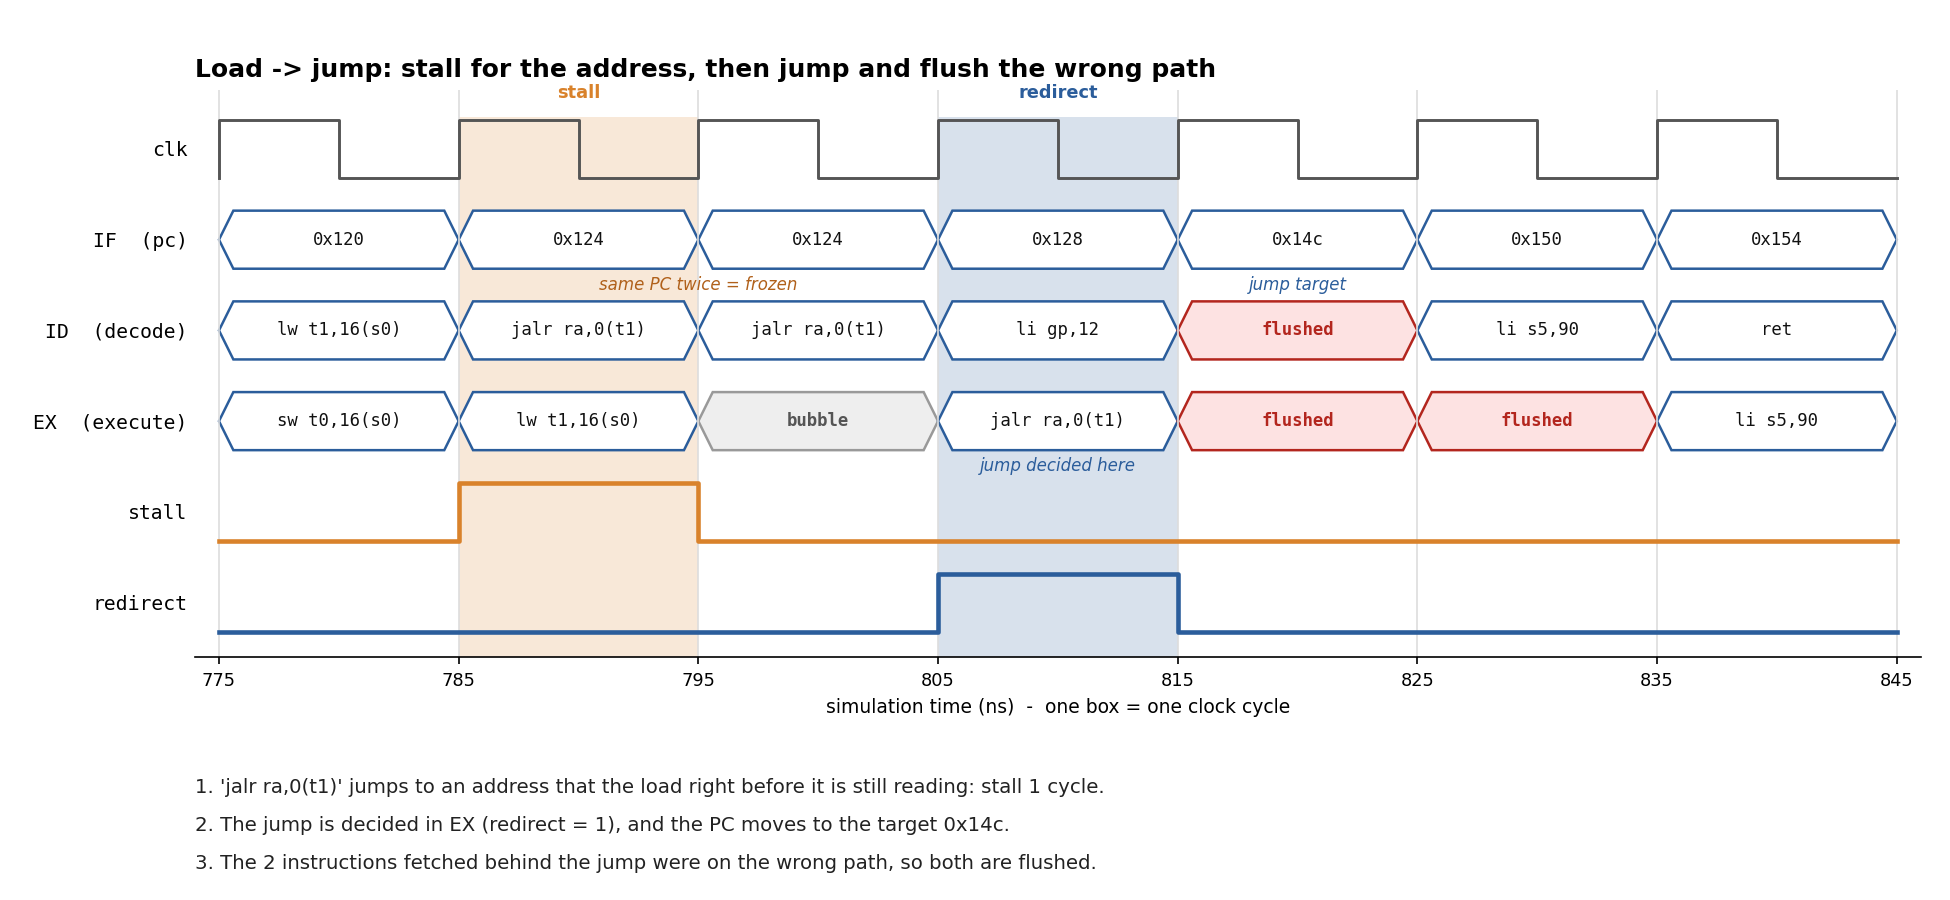

In [5]:
# 5. record a waveform of hazard_test and draw the annotated pictures
!python scripts/run.py wave hazard_test
!python scripts/plot_wave.py
from IPython.display import Image, display
display(Image("docs/waveform_load_use_stall.png"))
display(Image("docs/waveform_jalr_flush.png"))